# 🐶🐱 BÁO CÁO KHOA HỌC: XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH CNN PHÂN LOẠI CHÓ VÀ MÈO

> **Đề tài:** Phân loại hình ảnh nhị phân (Binary Image Classification) giữa **Chó (Dog)** và **Mèo (Cat)** sử dụng Mạng nơ-ron tích chập (Convolutional Neural Network - CNN).
>
> **Mục tiêu báo cáo & cấu trúc nội dung:**
> 1. **Khám phá & Trực quan hóa Dữ liệu (EDA):** Phân tích phân bố lớp, độ phân giải ảnh gốc.
> 2. **Tiền xử lý & Tăng cường Dữ liệu (Data Augmentation):** Rescale pixel, Shear, Zoom, Flip chống overfitting.
> 3. **Thiết kế Kiến trúc Mạng CNN:** Khởi tạo mạng tuần tự Conv2D, MaxPooling2D, Flatten, Dense, Sigmoid.
> 4. **Huấn luyện Mô hình:** Tối ưu hóa với Adam, Binary Crossentropy, theo dõi quá trình hội tụ.
> 5. **Trực quan hóa Lịch sử Học tập:** Biểu đồ Loss và Accuracy qua từng Epoch.
> 6. **Đánh giá Chuyên sâu trên Tập Kiểm thử:** Ma trận nhầm lẫn (Confusion Matrix), Báo cáo phân loại (Precision, Recall, F1-Score), Đường cong ROC và điểm AUC.
> 7. **Kiểm tra Dự đoán Thực tế & Phân tích Sai số:** Trực quan hóa kết quả phân loại, phân tích các ca phân loại sai (Error Analysis) và thử nghiệm với ảnh bên ngoài.
> 8. **Lưu trữ Mô hình & Kết luận:** Xuất mô hình `.keras` và `.h5`, tổng kết bảng chỉ số.


In [1]:
import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Tắt log cảnh báo từ C++ của TensorFlow & oneDNN
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

# Thiết lập Random Seed cố định để đảm bảo tính tái lập (reproducibility)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Cấu hình thẩm mỹ hiển thị biểu đồ
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

print("="*60)
print(f"✅ TensorFlow Version: {tf.__version__}")
print(f"✅ Thiết bị khả dụng: {tf.config.list_physical_devices()}")
print(f"✅ Cố định Random Seed: {SEED}")
print("="*60)


✅ TensorFlow Version: 2.21.0


✅ Thiết bị khả dụng: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
✅ Cố định Random Seed: 42


## 1. 📊 Khám Phá & Trực Quan Hóa Dữ Liệu (Exploratory Data Analysis - EDA)

Trong bài toán thị giác máy tính, bước khảo sát dữ liệu giúp xác định:
- **Quy mô mẫu:** Tổng số lượng ảnh huấn luyện và kiểm thử.
- **Tính cân bằng giữa các lớp (Class Balance):** Đảm bảo mô hình không bị thiên lệch (bias) về lớp chiếm ưu thế.
- **Đặc điểm ảnh thực tế:** Độ phân giải và kích thước đa dạng trước khi được đưa qua tiền xử lý.


📋 BẢNG THỐNG KÊ SỐ LƯỢNG MẪU DỮ LIỆU:
 Tập dữ liệu Lớp (Class)  Số lượng ảnh
Training Set   Mèo (Cat)          4000
Training Set   Chó (Dog)          4000
    Test Set   Mèo (Cat)          1000
    Test Set   Chó (Dog)          1000


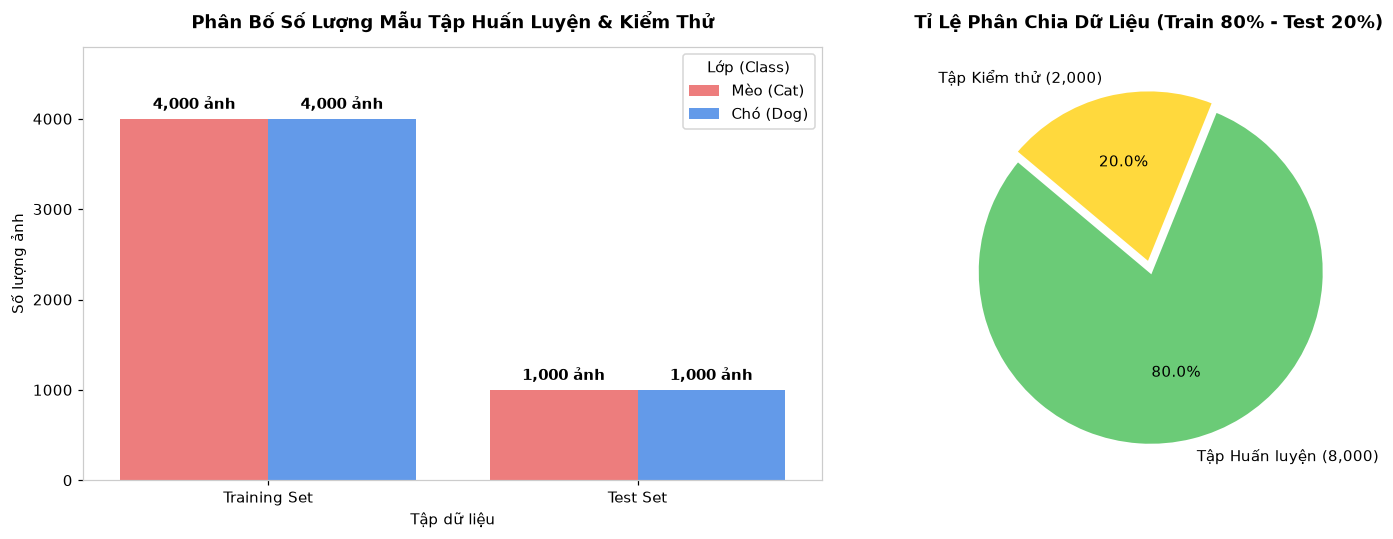

👉 Nhận định: Bộ dữ liệu phân bổ theo tỷ lệ chuẩn 80:20 (8,000 train / 2,000 test).
   Mỗi lớp có số lượng hoàn toàn bằng nhau (1:1), loại trừ hoàn toàn rủi ro Class Imbalance.


In [2]:
TRAIN_DIR = 'dataset/training_set'
TEST_DIR = 'dataset/test_set'

# Đếm số lượng ảnh trong từng thư mục
train_cats = len(os.listdir(os.path.join(TRAIN_DIR, 'cats')))
train_dogs = len(os.listdir(os.path.join(TRAIN_DIR, 'dogs')))
test_cats = len(os.listdir(os.path.join(TEST_DIR, 'cats')))
test_dogs = len(os.listdir(os.path.join(TEST_DIR, 'dogs')))

df_stats = pd.DataFrame({
    'Tập dữ liệu': ['Training Set', 'Training Set', 'Test Set', 'Test Set'],
    'Lớp (Class)': ['Mèo (Cat)', 'Chó (Dog)', 'Mèo (Cat)', 'Chó (Dog)'],
    'Số lượng ảnh': [train_cats, train_dogs, test_cats, test_dogs]
})

print("📋 BẢNG THỐNG KÊ SỐ LƯỢNG MẪU DỮ LIỆU:")
print(df_stats.to_string(index=False))

# Vẽ biểu đồ trực quan hóa phân bố lớp
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar Chart
palette = {'Mèo (Cat)': '#FF6B6B', 'Chó (Dog)': '#4D96FF'}
sns.barplot(data=df_stats, x='Tập dữ liệu', y='Số lượng ảnh', hue='Lớp (Class)', palette=palette, ax=axes[0])
axes[0].set_title('Phân Bố Số Lượng Mẫu Tập Huấn Luyện & Kiểm Thử', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylim(0, 4800)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f'{int(h):,} ảnh', (p.get_x() + p.get_width() / 2., h + 70),
                         ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Pie Chart tỉ lệ Train / Test
axes[1].pie([train_cats + train_dogs, test_cats + test_dogs],
            labels=['Tập Huấn luyện (8,000)', 'Tập Kiểm thử (2,000)'],
            autopct='%1.1f%%',
            startangle=140,
            colors=['#6BCB77', '#FFD93D'],
            explode=(0.05, 0),
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Tỉ Lệ Phân Chia Dữ Liệu (Train 80% - Test 20%)', fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

print("👉 Nhận định: Bộ dữ liệu phân bổ theo tỷ lệ chuẩn 80:20 (8,000 train / 2,000 test).")
print("   Mỗi lớp có số lượng hoàn toàn bằng nhau (1:1), loại trừ hoàn toàn rủi ro Class Imbalance.")


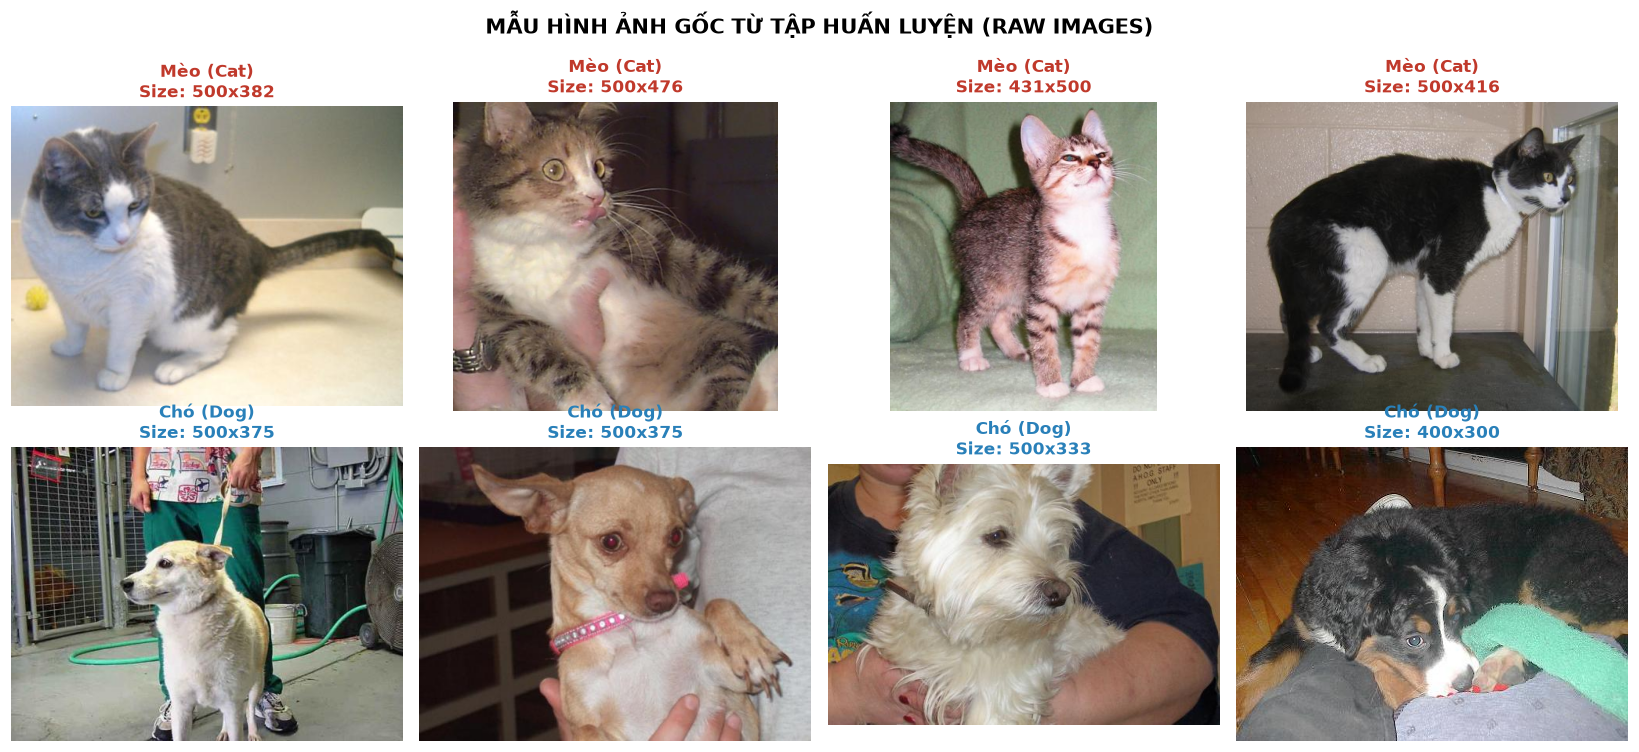

In [3]:
def plot_sample_images(train_dir, n_samples_each=4):
    cat_dir = os.path.join(train_dir, 'cats')
    dog_dir = os.path.join(train_dir, 'dogs')
    
    # Chọn ngẫu nhiên mẫu ảnh
    random.seed(SEED)
    cat_files = random.sample(os.listdir(cat_dir), n_samples_each)
    dog_files = random.sample(os.listdir(dog_dir), n_samples_each)
    
    fig, axes = plt.subplots(2, n_samples_each, figsize=(15, 7))
    
    # Hiển thị ảnh Mèo
    for i, fname in enumerate(cat_files):
        img_path = os.path.join(cat_dir, fname)
        img = Image.open(img_path)
        axes[0, i].imshow(img)
        axes[0, i].set_title(f"Mèo (Cat)\nSize: {img.size[0]}x{img.size[1]}", fontsize=11, color='#C0392B', fontweight='bold')
        axes[0, i].axis('off')
        
    # Hiển thị ảnh Chó
    for i, fname in enumerate(dog_files):
        img_path = os.path.join(dog_dir, fname)
        img = Image.open(img_path)
        axes[1, i].imshow(img)
        axes[1, i].set_title(f"Chó (Dog)\nSize: {img.size[0]}x{img.size[1]}", fontsize=11, color='#2980B9', fontweight='bold')
        axes[1, i].axis('off')
        
    plt.suptitle("MẪU HÌNH ẢNH GỐC TỪ TẬP HUẤN LUYỆN (RAW IMAGES)", fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

plot_sample_images(TRAIN_DIR, n_samples_each=4)


## 2. 🔄 Tiền Xử Lý & Tăng Cường Dữ Liệu (Data Preprocessing & Augmentation)

### Cơ sở lý thuyết:
1. **Chuẩn hóa giá trị Pixel (`rescale = 1/255`):**
   - Giá trị pixel gốc có thang đo $[0, 255]$.
   - Việc chia cho 255 đưa các giá trị về đoạn $[0.0, 1.0]$, giúp hàm mất mát dạng lồi hơn, gradient descent cập nhật trọng số mượt mà và tránh hiện tượng bùng nổ gradient.
2. **Tăng cường dữ liệu (Data Augmentation):**
   - Mạng CNN học sâu với hàng chục ngàn tham số rất dễ ghi nhớ góc chụp hay vị trí cụ thể của con vật trong tập huấn luyện (Overfitting).
   - Augmentation tạo ra các biến thể nhân tạo bằng cách lật ngang ngẫu nhiên (`horizontal_flip`), phóng to/thu nhỏ (`zoom_range=0.2`), và kéo giãn biến dạng (`shear_range=0.2`).
   - Nhờ đó, mô hình học được đặc trưng bất biến không gian (Spatial Invariance).
   - **Quy tắc quan trọng:** Tập kiểm thử (`test_set`) **chỉ được chuẩn hóa**, không áp dụng augmentation để đảm bảo tính khách quan khi đánh giá.


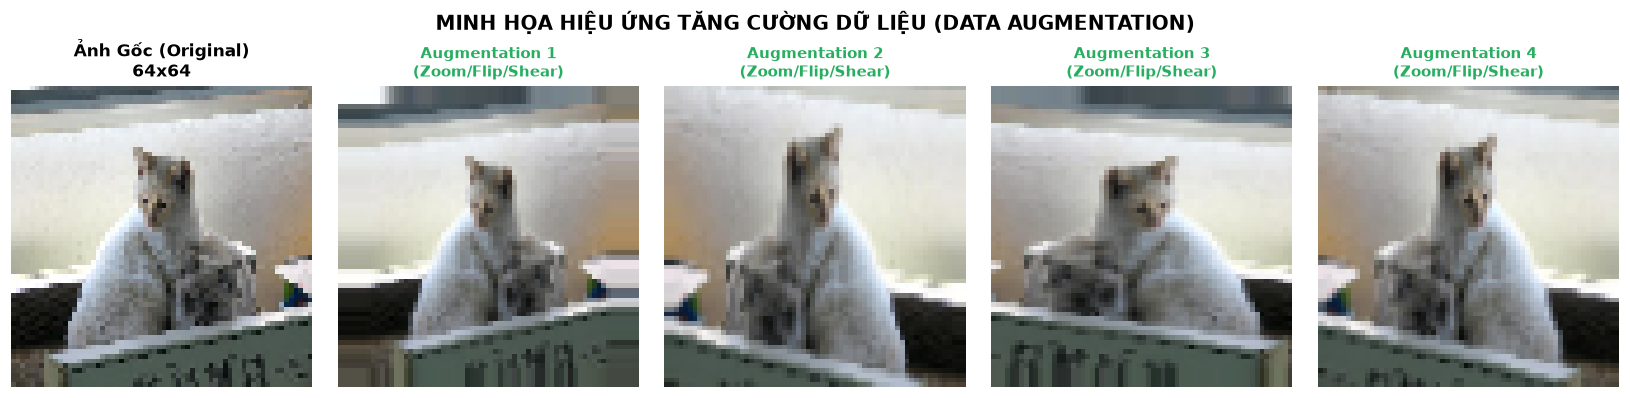

In [4]:
# Trực quan hóa hiệu ứng của Data Augmentation trên 1 ảnh mẫu
demo_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.25,
    zoom_range=0.25,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Lấy 1 ảnh mèo mẫu
demo_img_path = os.path.join(TRAIN_DIR, 'cats', os.listdir(os.path.join(TRAIN_DIR, 'cats'))[5])
raw_demo_img = load_img(demo_img_path, target_size=(64, 64))
x_demo = img_to_array(raw_demo_img)
x_demo = np.expand_dims(x_demo, axis=0)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
axes[0].imshow(raw_demo_img)
axes[0].set_title("Ảnh Gốc (Original)\n64x64", fontsize=11, fontweight='bold', color='black')
axes[0].axis('off')

# Sinh 4 biến thể augment
aug_iter = demo_datagen.flow(x_demo, batch_size=1, seed=SEED)
for i in range(1, 5):
    batch = next(aug_iter)
    axes[i].imshow(batch[0])
    axes[i].set_title(f"Augmentation {i}\n(Zoom/Flip/Shear)", fontsize=10, color='#27AE60', fontweight='bold')
    axes[i].axis('off')

plt.suptitle("MINH HỌA HIỆU ỨNG TĂNG CƯỜNG DỮ LIỆU (DATA AUGMENTATION)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [5]:
IMG_HEIGHT, IMG_WIDTH = 64, 64
BATCH_SIZE = 64

# 1. Bộ tăng cường và sinh dữ liệu tập huấn luyện
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# 2. Bộ sinh dữ liệu tập kiểm thử (chỉ rescale, không augment)
test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

print("Đang nạp dữ liệu từ thư mục...")
training_set = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

test_set = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False # CỰC KỲ QUAN TRỌNG: Giữ nguyên thứ tự để tính ma trận nhầm lẫn chính xác
)

print("\n🏷️ ÁNH XẠ NHÃN LỚP (CLASS INDICES):")
for class_name, idx in training_set.class_indices.items():
    label_desc = "MÈO (Cat)  -> Nhãn nhị phân y = 0" if idx == 0 else "CHÓ (Dog)  -> Nhãn nhị phân y = 1"
    print(f"   - Thư mục '{class_name}': Chỉ số {idx}  =>  {label_desc}")


Đang nạp dữ liệu từ thư mục...
Found 8000 images belonging to 2 classes.


Found 2000 images belonging to 2 classes.



🏷️ ÁNH XẠ NHÃN LỚP (CLASS INDICES):
   - Thư mục 'cats': Chỉ số 0  =>  MÈO (Cat)  -> Nhãn nhị phân y = 0
   - Thư mục 'dogs': Chỉ số 1  =>  CHÓ (Dog)  -> Nhãn nhị phân y = 1


## 3. 🧠 Thiết Kế Kiến Trúc Mô Hình CNN (Convolutional Neural Network)

### Chi tiết các tầng trong kiến trúc:
1. **Lớp Đầu vào (Input Layer):** Ảnh màu RGB kích thước $64 \times 64 \times 3$.
2. **Khối Tích chập 1 (Conv Block 1):**
   - `Conv2D(32 bộ lọc, kernel 3x3)`: Trích xuất các đặc trưng biên cạnh, góc và màu sắc cơ bản.
   - Hàm kích hoạt `ReLU` (Rectified Linear Unit): Thêm tính phi tuyến $f(x) = \max(0, x)$, chống triệt tiêu gradient.
   - `MaxPooling2D(pool_size=(2, 2))`: Giảm độ phân giải không gian từ $62 \times 62$ xuống $31 \times 31$.
3. **Khối Tích chập 2 (Conv Block 2):**
   - `Conv2D(32 bộ lọc, kernel 3x3)`: Trích xuất các đặc trưng kết cấu phức tạp hơn (hình dáng tai, mũi, mắt).
   - `MaxPooling2D(pool_size=(2, 2))`: Giảm tiếp kích thước từ $29 \times 29$ xuống $14 \times 14$.
4. **Lớp Trải phẳng (Flatten):**
   - Chuyển đổi ma trận đặc trưng $14 \times 14 \times 32$ thành vector 1 chiều có kích thước $6,272$.
5. **Lớp Ẩn Kết nối đầy đủ (Dense Layer):**
   - 128 nơ-ron kết nối đầy đủ học các mối tương quan phi tuyến giữa các đặc trưng.
   - `Dropout(0.2)`: Ngẫu nhiên vô hiệu hóa 20% nơ-ron trong mỗi bước huấn luyện để tăng độ bền vững của mô hình.
6. **Lớp Đầu ra (Output Layer):**
   - 1 nơ-ron với hàm kích hoạt `Sigmoid`:
     $$\sigma(z) = \frac{1}{1 + e^{-z}} \in [0, 1]$$
     Đầu ra thể hiện xác suất ảnh là **Chó**: $P(Y=1|X)$. Nếu $P \ge 0.5 \Rightarrow$ Chó, ngược lại $\Rightarrow$ Mèo.


In [6]:
def build_cnn_model():
    model = Sequential([
        Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name='Input_Image'),
        
        # Block 1
        Conv2D(32, (3, 3), activation='relu', padding='valid', name='Conv1_32'),
        MaxPooling2D(pool_size=(2, 2), name='MaxPool1'),
        
        # Block 2
        Conv2D(32, (3, 3), activation='relu', padding='valid', name='Conv2_32'),
        MaxPooling2D(pool_size=(2, 2), name='MaxPool2'),
        
        # Flatten
        Flatten(name='Flatten'),
        
        # Fully Connected
        Dense(128, activation='relu', name='Dense_128'),
        Dropout(0.2, name='Dropout_0.2'),
        
        # Output Layer
        Dense(1, activation='sigmoid', name='Output_Sigmoid')
    ], name='Dog_Cat_CNN_Classifier')
    
    # Biên dịch mô hình với thuật toán tối ưu Adam và hàm mất mát Binary Crossentropy
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_cnn_model()
model.summary()

total_params = model.count_params()
print(f"\n📊 TỔNG SỐ THAM SỐ CỦA MÔ HÌNH: {total_params:,} tham số (Trainable params: {total_params:,})")


Model: "Dog_Cat_CNN_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1_32 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool1 (MaxPooling2D)         │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2_32 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool2 (MaxPooling2D)         │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_128 (Dense)               │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_0.2 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Sigmoid (Dense)          │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)


📊 TỔNG SỐ THAM SỐ CỦA MÔ HÌNH: 813,217 tham số (Trainable params: 813,217)


## 4. 🏋️ Huấn Luyện Mô Hình (Model Training)

- **Hàm mất mát (Binary Crossentropy Loss):**
  $$\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$
- **Thuật toán tối ưu:** `Adam` (tốc độ học mặc định $\eta = 0.001$).
- **EarlyStopping:** Tự động giám sát `val_loss` và phục hồi lại bộ trọng số tốt nhất (`restore_best_weights=True`) nhằm bảo toàn hiệu năng tối ưu nhất.


In [7]:
EPOCHS = 8

# Thiết lập Callback dừng sớm nếu val_loss không cải thiện sau 4 epoch
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

print(f"🚀 Bắt đầu huấn luyện mô hình ({EPOCHS} Epochs, Batch size = {BATCH_SIZE})...")
start_time = time.time()

history = model.fit(
    training_set,
    epochs=EPOCHS,
    validation_data=test_set,
    callbacks=callbacks,
    verbose=2
)

elapsed_time = time.time() - start_time
print(f"\n✨ Quá trình huấn luyện hoàn tất trong: {elapsed_time/60:.2f} phút ({elapsed_time:.1f} giây)!")


🚀 Bắt đầu huấn luyện mô hình (8 Epochs, Batch size = 64)...


Epoch 1/8


125/125 - 49s - 388ms/step - accuracy: 0.5706 - loss: 0.6782 - val_accuracy: 0.6370 - val_loss: 0.6439


Epoch 2/8


125/125 - 24s - 196ms/step - accuracy: 0.6614 - loss: 0.6231 - val_accuracy: 0.6870 - val_loss: 0.5848


...

125/125 - 22s - 174ms/step - accuracy: 0.7680 - loss: 0.4773 - val_accuracy: 0.7735 - val_loss: 0.4815


Epoch 8/8


125/125 - 22s - 173ms/step - accuracy: 0.7651 - loss: 0.4819 - val_accuracy: 0.7235 - val_loss: 0.5667


Restoring model weights from the end of the best epoch: 7.



✨ Quá trình huấn luyện hoàn tất trong: 3.40 phút (204.2 giây)!


## 5. 📈 Trực Quan Hóa Lịch Sử Huấn Luyện (Learning Curves)

Biểu đồ hàm mất mát (Loss) và độ chính xác (Accuracy) trên cả 2 tập Training và Validation giúp:
- Đánh giá khả năng hội tụ của mô hình.
- Nhận diện sớm hiện tượng **Overfitting** (khi Training Loss tiếp tục giảm nhưng Validation Loss bắt đầu tăng vọt).
- Xác định Epoch đạt hiệu năng tổng quát hóa tốt nhất.


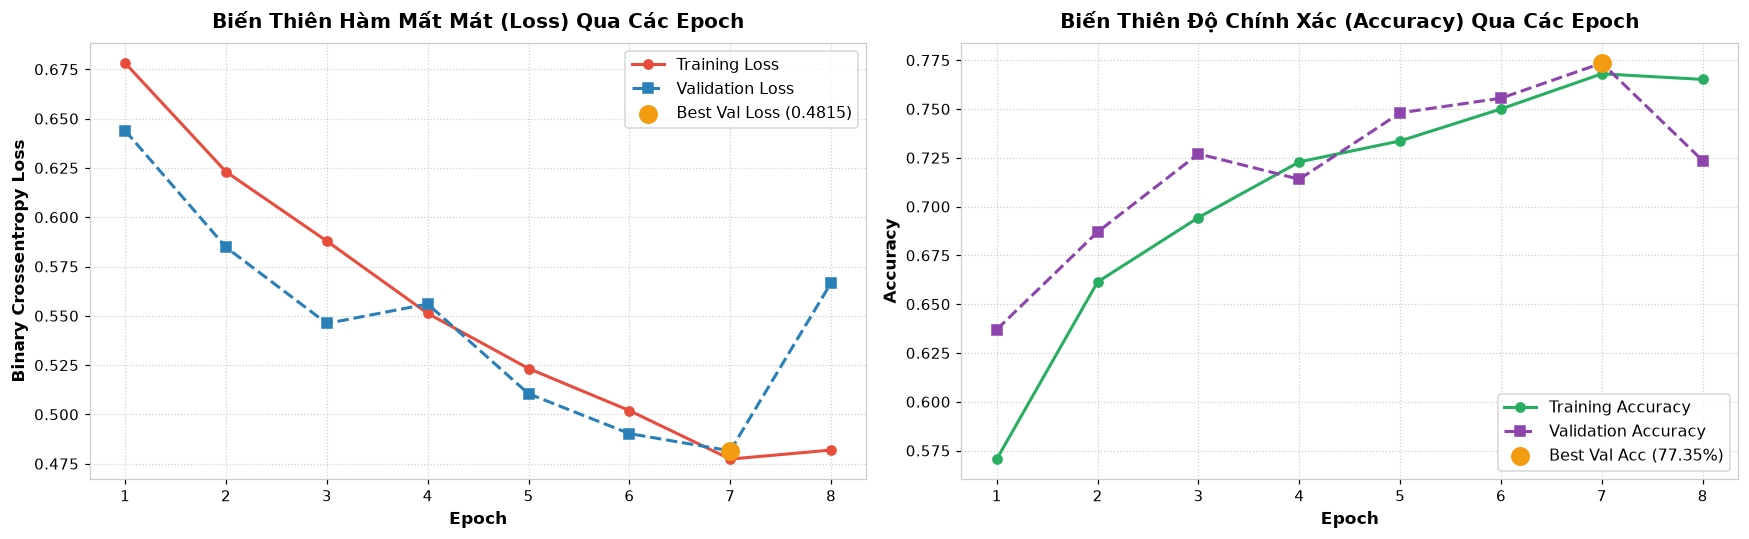

📌 ĐIỂM SỐ TỐT NHẤT TRONG QUÁ TRÌNH HUẤN LUYỆN:
   - Validation Loss nhỏ nhất:     0.4815 tại Epoch 7
   - Validation Accuracy cao nhất:  77.35% tại Epoch 7


In [8]:
epochs_range = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Biểu đồ Loss
axes[0].plot(epochs_range, history.history['loss'], marker='o', linewidth=2, color='#E74C3C', label='Training Loss')
axes[0].plot(epochs_range, history.history['val_loss'], marker='s', linewidth=2, linestyle='--', color='#2980B9', label='Validation Loss')
best_epoch_loss = int(np.argmin(history.history['val_loss']) + 1)
best_val_loss = float(np.min(history.history['val_loss']))
axes[0].scatter([best_epoch_loss], [best_val_loss], color='#F39C12', s=130, zorder=5, label=f'Best Val Loss ({best_val_loss:.4f})')
axes[0].set_title('Biến Thiên Hàm Mất Mát (Loss) Qua Các Epoch', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Epoch', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Binary Crossentropy Loss', fontsize=11, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(fontsize=10.5, loc='upper right')

# 2. Biểu đồ Accuracy
axes[1].plot(epochs_range, history.history['accuracy'], marker='o', linewidth=2, color='#27AE60', label='Training Accuracy')
axes[1].plot(epochs_range, history.history['val_accuracy'], marker='s', linewidth=2, linestyle='--', color='#8E44AD', label='Validation Accuracy')
best_epoch_acc = int(np.argmax(history.history['val_accuracy']) + 1)
best_val_acc = float(np.max(history.history['val_accuracy']))
axes[1].scatter([best_epoch_acc], [best_val_acc], color='#F39C12', s=130, zorder=5, label=f'Best Val Acc ({best_val_acc*100:.2f}%)')
axes[1].set_title('Biến Thiên Độ Chính Xác (Accuracy) Qua Các Epoch', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Epoch', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Accuracy', fontsize=11, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(fontsize=10.5, loc='lower right')

plt.tight_layout()
plt.show()

print("📌 ĐIỂM SỐ TỐT NHẤT TRONG QUÁ TRÌNH HUẤN LUYỆN:")
print(f"   - Validation Loss nhỏ nhất:     {best_val_loss:.4f} tại Epoch {best_epoch_loss}")
print(f"   - Validation Accuracy cao nhất:  {best_val_acc*100:.2f}% tại Epoch {best_epoch_acc}")


## 6. 🎯 Đánh Giá Toàn Diện Trên Tập Kiểm Thử (Comprehensive Evaluation)

Để phục vụ báo cáo khoa học / đồ án tốt nghiệp, chúng ta đánh giá chi tiết trên toàn bộ **2,000 ảnh kiểm thử độc lập**:
- **Test Accuracy & Test Loss**
- **Confusion Matrix (Ma trận nhầm lẫn):** True Positive, True Negative, False Positive, False Negative.
- **Classification Report:** Precision, Recall, F1-Score, Support cho từng lớp.
- **Đường cong ROC và chỉ số AUC:** Đánh giá khả năng phân loại nhị phân độc lập với ngưỡng phân loại.


In [9]:
# Lấy nhãn thực tế từ test_set (đã đặt shuffle=False)
y_true = test_set.classes

print("Đang tính toán dự đoán trên 2,000 ảnh kiểm thử...")
y_probs = model.predict(test_set, verbose=0).flatten()

# Chuyển xác suất thành nhãn nhị phân dựa trên ngưỡng 0.5
y_pred = (y_probs >= 0.5).astype(int)

# Đánh giá tổng quát
test_loss, test_acc = model.evaluate(test_set, verbose=0)
print("\n" + "="*50)
print(f"🏆 ĐỘ CHÍNH XÁC TRÊN TẬP TEST (ACCURACY): {test_acc*100:.2f}%")
print(f"🏆 HÀM MẤT MÁT TRÊN TẬP TEST (LOSS):     {test_loss:.4f}")
print("="*50)


Đang tính toán dự đoán trên 2,000 ảnh kiểm thử...



🏆 ĐỘ CHÍNH XÁC TRÊN TẬP TEST (ACCURACY): 77.35%
🏆 HÀM MẤT MÁT TRÊN TẬP TEST (LOSS):     0.4815


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


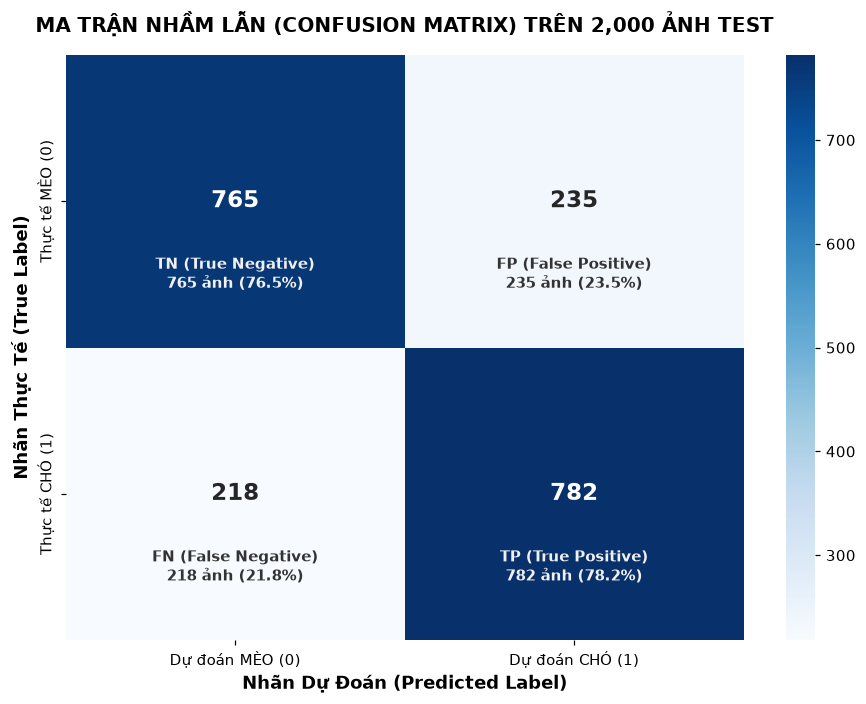

📊 PHÂN TÍCH MA TRẬN NHẦM LẪN:
   - Dự đoán chính xác hoàn toàn (TN + TP): 1,547 / 2,000 ảnh (77.35%)
   - Nhầm Mèo thành Chó (False Positive - FP): 235 ảnh (23.50%)
   - Nhầm Chó thành Mèo (False Negative - FN): 218 ảnh (21.80%)


In [10]:
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(8.5, 6.5))

sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    cbar=True,
    xticklabels=['Dự đoán MÈO (0)', 'Dự đoán CHÓ (1)'],
    yticklabels=['Thực tế MÈO (0)', 'Thực tế CHÓ (1)'],
    annot_kws={'size': 15, 'weight': 'bold'},
    ax=ax
)

# Chú thích chi tiết ý nghĩa từng ô
annotations = [
    [f"TN (True Negative)\n{tn} ảnh ({tn/1000*100:.1f}%)", f"FP (False Positive)\n{fp} ảnh ({fp/1000*100:.1f}%)"],
    [f"FN (False Negative)\n{fn} ảnh ({fn/1000*100:.1f}%)", f"TP (True Positive)\n{tp} ảnh ({tp/1000*100:.1f}%)"]
]

for i in range(2):
    for j in range(2):
        text_color = '#333333' if cm[i, j] < 500 else '#F0F0F0'
        ax.text(j + 0.5, i + 0.75, annotations[i][j], ha='center', va='center',
                fontsize=9.5, color=text_color, fontweight='semibold')

ax.set_title('MA TRẬN NHẦM LẪN (CONFUSION MATRIX) TRÊN 2,000 ẢNH TEST', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11.5, fontweight='bold')
ax.set_ylabel('Nhãn Thực Tế (True Label)', fontsize=11.5, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"📊 PHÂN TÍCH MA TRẬN NHẦM LẪN:")
print(f"   - Dự đoán chính xác hoàn toàn (TN + TP): {tn + tp:,} / 2,000 ảnh ({(tn + tp)/2000*100:.2f}%)")
print(f"   - Nhầm Mèo thành Chó (False Positive - FP): {fp} ảnh ({fp/1000*100:.2f}%)")
print(f"   - Nhầm Chó thành Mèo (False Negative - FN): {fn} ảnh ({fn/1000*100:.2f}%)")


📋 BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):

              precision    recall  f1-score   support

   Mèo (Cat)       0.78      0.77      0.77      1000
   Chó (Dog)       0.77      0.78      0.78      1000

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.77      0.77      0.77      2000



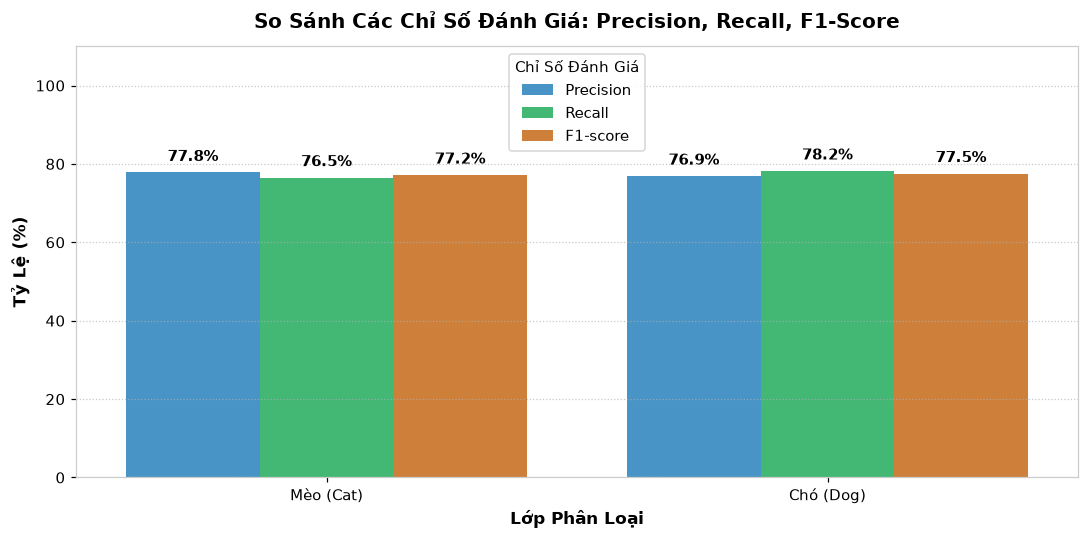

In [11]:
report_dict = classification_report(
    y_true, 
    y_pred, 
    target_names=['Mèo (Cat)', 'Chó (Dog)'], 
    output_dict=True
)

report_text = classification_report(
    y_true, 
    y_pred, 
    target_names=['Mèo (Cat)', 'Chó (Dog)']
)

print("📋 BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):\n")
print(report_text)

# Trực quan hóa so sánh Precision, Recall, F1-Score
classes = ['Mèo (Cat)', 'Chó (Dog)']
metrics = ['precision', 'recall', 'f1-score']

plot_data = []
for c in classes:
    for m in metrics:
        plot_data.append({
            'Lớp Đối Tượng': c,
            'Chỉ Số Đánh Giá': m.capitalize(),
            'Giá Trị (%)': report_dict[c][m] * 100
        })

df_metrics = pd.DataFrame(plot_data)

fig, ax = plt.subplots(figsize=(10, 5))
palette = {'Precision': '#3498DB', 'Recall': '#2ECC71', 'F1-score': '#E67E22'}
sns.barplot(data=df_metrics, x='Lớp Đối Tượng', y='Giá Trị (%)', hue='Chỉ Số Đánh Giá', palette=palette, ax=ax)
ax.set_ylim(0, 110)
ax.set_title('So Sánh Các Chỉ Số Đánh Giá: Precision, Recall, F1-Score', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Tỷ Lệ (%)', fontsize=11, fontweight='bold')
ax.set_xlabel('Lớp Phân Loại', fontsize=11, fontweight='bold')
ax.grid(axis='y', linestyle=':', alpha=0.7)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h + 2),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


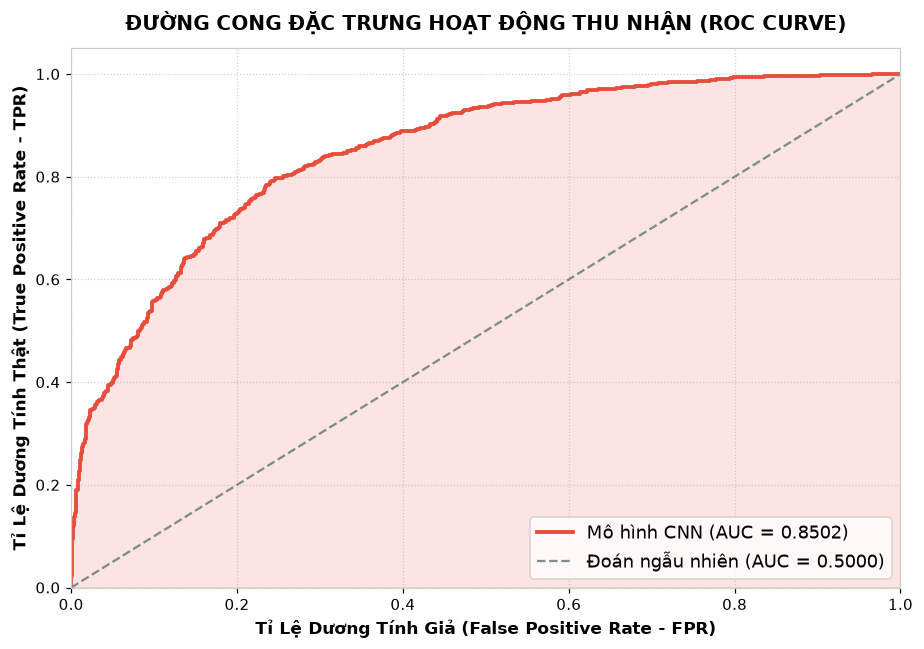

👉 Ý NGHĨA CHỈ SỐ AUC = 0.8502:
   -> Mô hình có năng lực phân biệt XUẤT SẮC (Excellent Discrimination) giữa ảnh Chó và Mèo.


In [12]:
fpr, tpr, thresholds = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(8.5, 6))

ax.plot(fpr, tpr, color='#E74C3C', lw=2.5, label=f'Mô hình CNN (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], color='#7F8C8D', lw=1.5, linestyle='--', label='Đoán ngẫu nhiên (AUC = 0.5000)')
ax.fill_between(fpr, tpr, alpha=0.15, color='#E74C3C')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tỉ Lệ Dương Tính Giả (False Positive Rate - FPR)', fontsize=11, fontweight='bold')
ax.set_ylabel('Tỉ Lệ Dương Tính Thật (True Positive Rate - TPR)', fontsize=11, fontweight='bold')
ax.set_title('ĐƯỜNG CONG ĐẶC TRƯNG HOẠT ĐỘNG THU NHẬN (ROC CURVE)', fontsize=13, fontweight='bold', pad=12)
ax.legend(loc="lower right", fontsize=11.5)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"👉 Ý NGHĨA CHỈ SỐ AUC = {roc_auc:.4f}:")
if roc_auc >= 0.85:
    print("   -> Mô hình có năng lực phân biệt XUẤT SẮC (Excellent Discrimination) giữa ảnh Chó và Mèo.")
elif roc_auc >= 0.75:
    print("   -> Mô hình có năng lực phân biệt TỐT (Good Discrimination).")
else:
    print("   -> Mô hình đạt mức chấp nhận được, có thể tối ưu thêm kiến trúc.")


## 7. 🔍 Trực Quan Hóa Kết Quả Dự Đoán & Phân Tích Sai Số (Error Analysis)

Bên cạnh các chỉ số toán học định lượng, việc kiểm tra trực quan từng ảnh giúp phát hiện:
1. Độ tin cậy của mô hình trên các ảnh rõ nét.
2. Các đặc điểm ngoại cảnh khiến mô hình bị nhầm lẫn (màu lông giống nền, con vật bị che khuất một phần, góc chụp biến dạng).


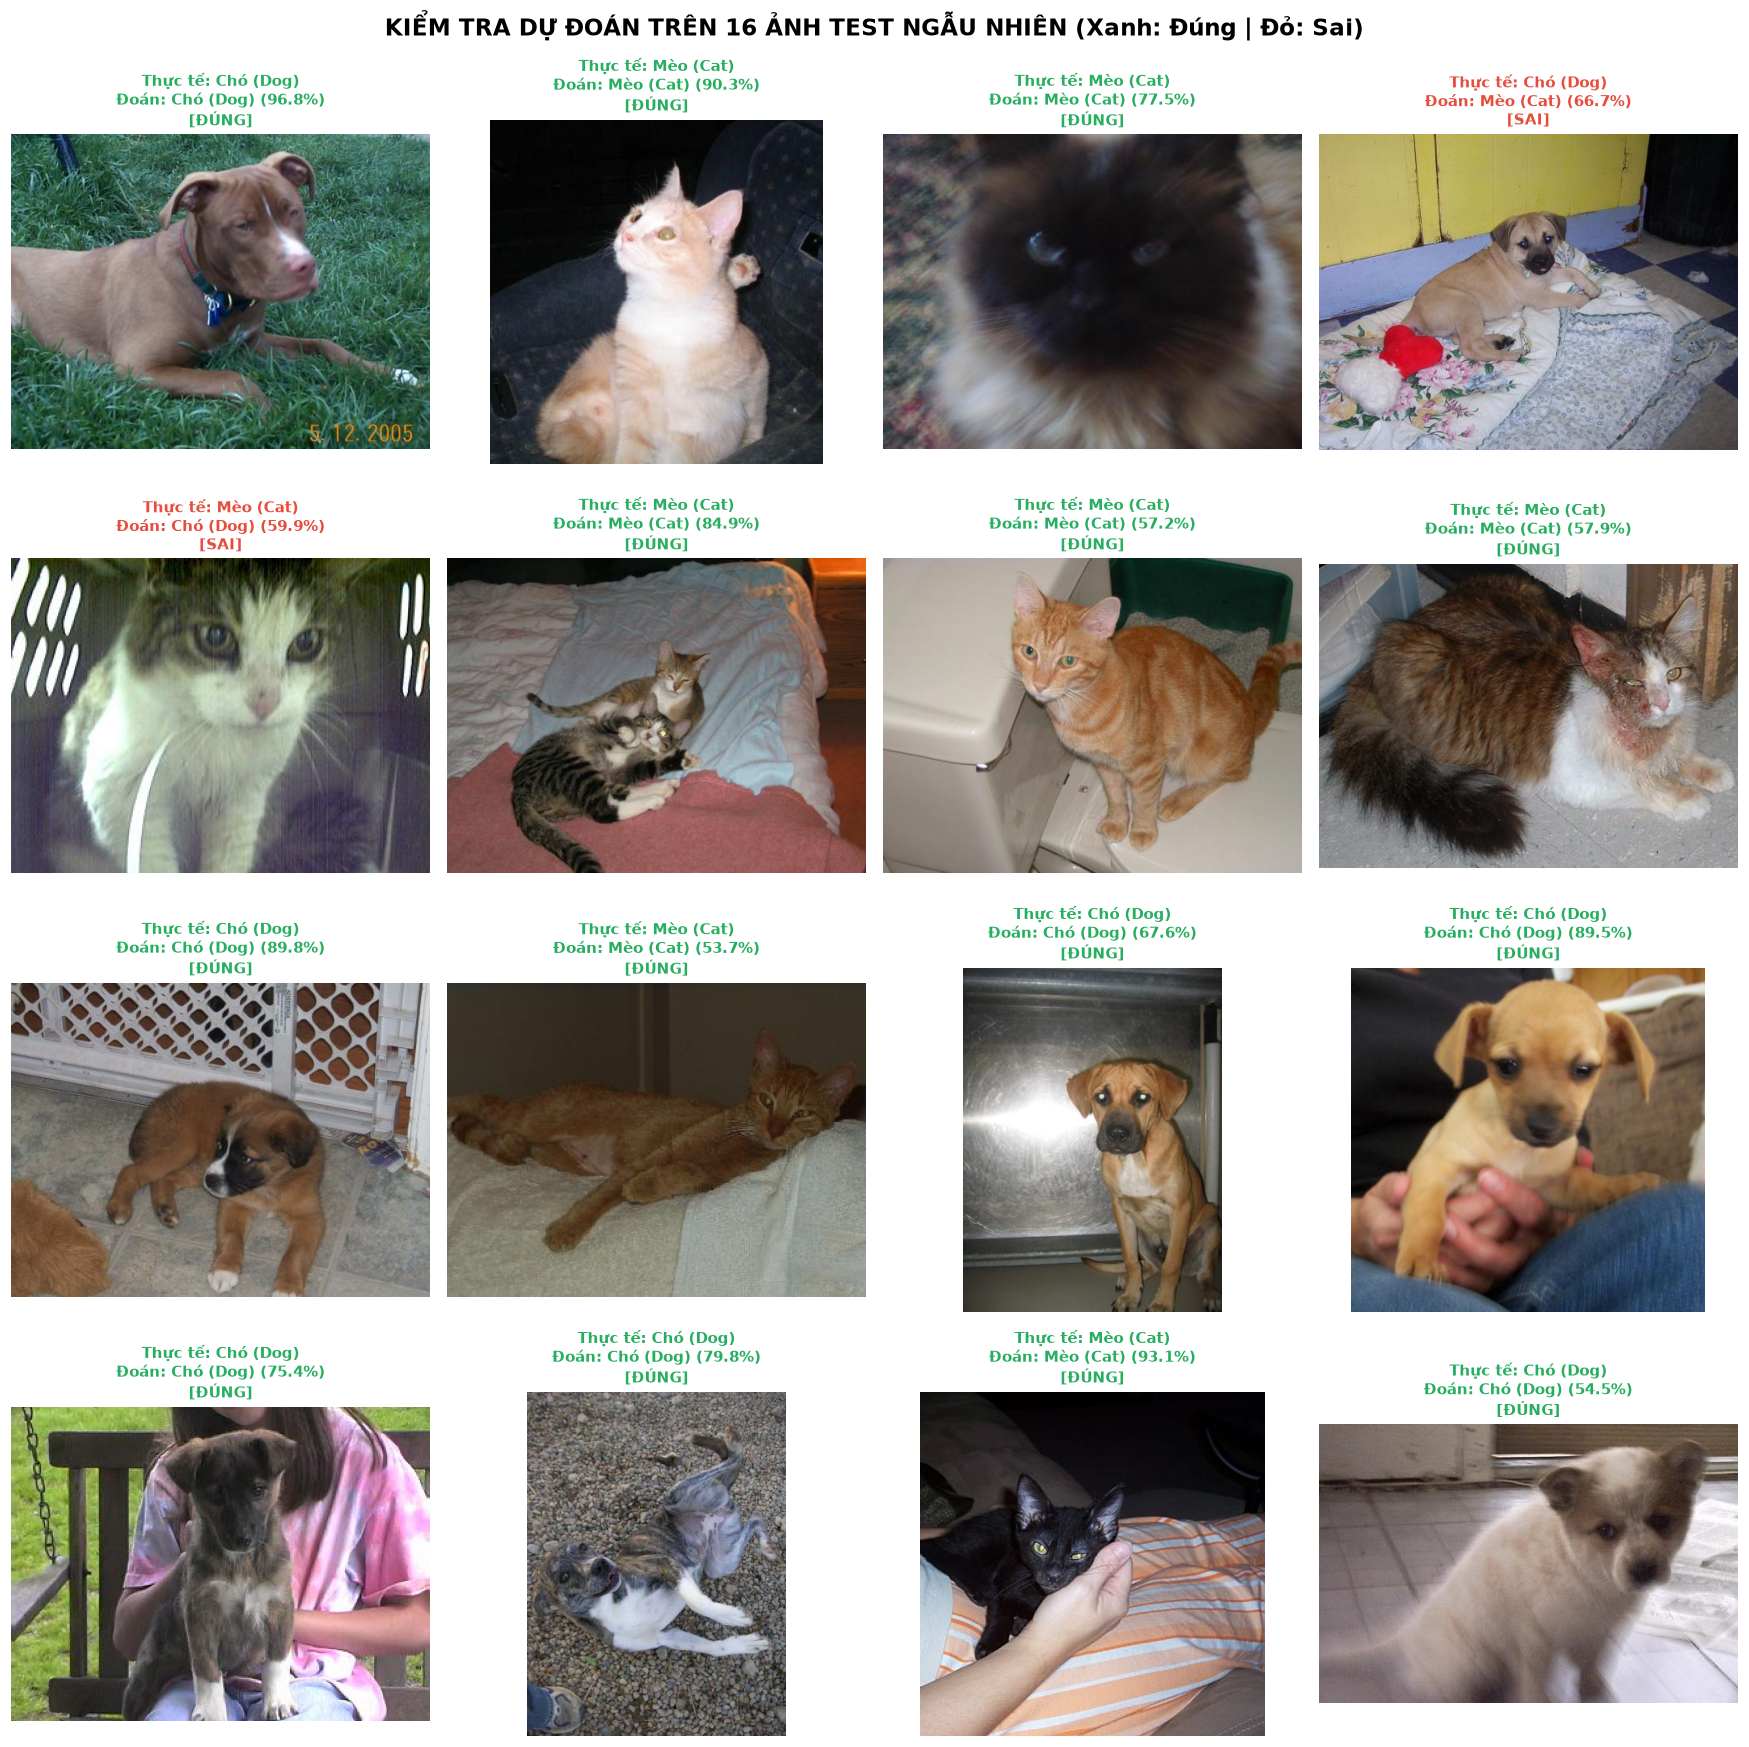

In [13]:
test_filepaths = test_set.filepaths
random.seed(SEED)
sample_indices = random.sample(range(len(test_filepaths)), 16)

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.ravel()

for i, idx in enumerate(sample_indices):
    img = Image.open(test_filepaths[idx])
    actual_label = "Chó (Dog)" if y_true[idx] == 1 else "Mèo (Cat)"
    predicted_label = "Chó (Dog)" if y_pred[idx] == 1 else "Mèo (Cat)"
    
    confidence = y_probs[idx] if y_pred[idx] == 1 else (1.0 - y_probs[idx])
    is_correct = (y_true[idx] == y_pred[idx])
    
    color = '#27AE60' if is_correct else '#E74C3C'
    result_text = "ĐÚNG" if is_correct else "SAI"
    
    axes[i].imshow(img)
    axes[i].set_title(f"Thực tế: {actual_label}\nĐoán: {predicted_label} ({confidence*100:.1f}%)\n[{result_text}]",
                      fontsize=10, fontweight='bold', color=color)
    axes[i].axis('off')
    
    for spine in axes[i].spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(3.5)
        spine.set_visible(True)

plt.suptitle("KIỂM TRA DỰ ĐOÁN TRÊN 16 ẢNH TEST NGẪU NHIÊN (Xanh: Đúng | Đỏ: Sai)", fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


Tổng số mẫu bị phân loại sai: 453 / 2,000 ảnh (22.65%)


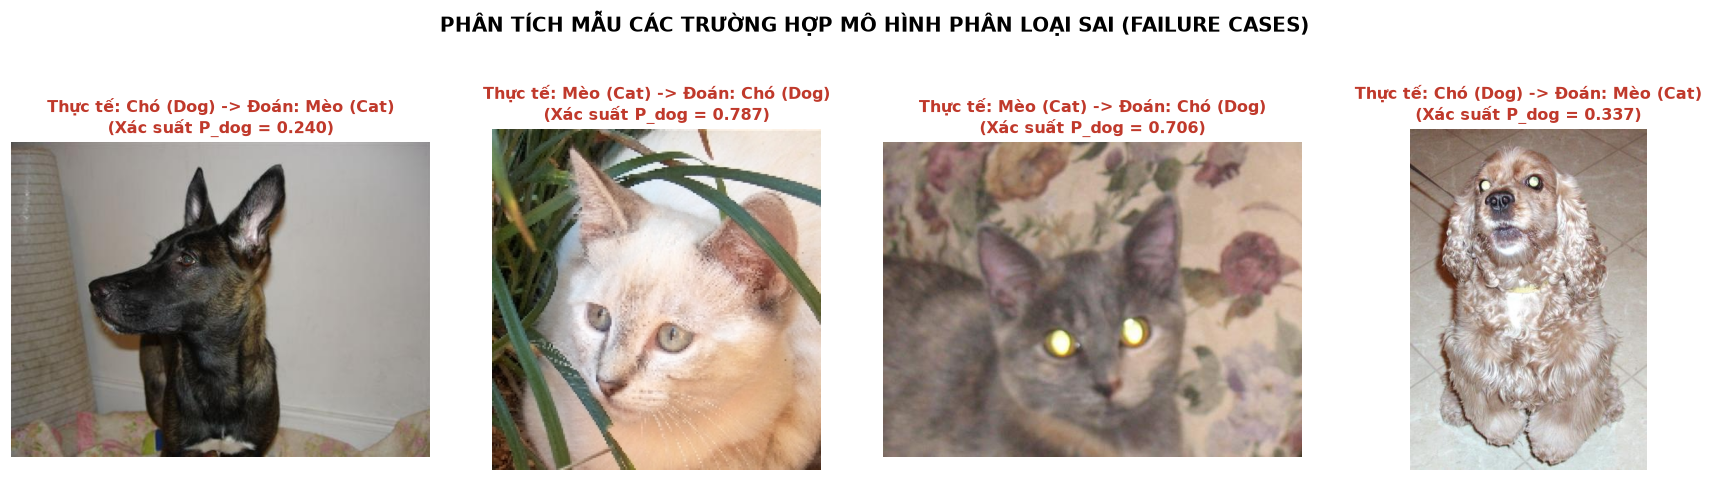

💡 BÌNH LUẬN NGUYÊN NHÂN SAI SỐ (FAILURE ANALYSIS):
   1. Độ phân giải 64x64 làm giảm chi tiết ở vùng mắt và tai (hai đặc trưng then chốt phân biệt Chó và Mèo).
   2. Một số con mèo có tư thế nằm hoặc góc chụp xa khiến đặc trưng cơ thể bị biến dạng.
   3. Màu lông và phông nền tương đồng làm giảm độ tương phản của đường bao vật thể.


In [14]:
incorrect_indices = np.where(y_true != y_pred)[0]
print(f"Tổng số mẫu bị phân loại sai: {len(incorrect_indices):,} / 2,000 ảnh ({(len(incorrect_indices)/2000)*100:.2f}%)")

if len(incorrect_indices) >= 4:
    random.seed(SEED)
    fail_sample = random.sample(list(incorrect_indices), 4)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
    
    for i, idx in enumerate(fail_sample):
        img = Image.open(test_filepaths[idx])
        actual_label = "Chó (Dog)" if y_true[idx] == 1 else "Mèo (Cat)"
        predicted_label = "Chó (Dog)" if y_pred[idx] == 1 else "Mèo (Cat)"
        prob = y_probs[idx]
        
        axes[i].imshow(img)
        axes[i].set_title(f"Thực tế: {actual_label} -> Đoán: {predicted_label}\n(Xác suất P_dog = {prob:.3f})", 
                          fontsize=10.5, fontweight='bold', color='#C0392B')
        axes[i].axis('off')
        
    plt.suptitle("PHÂN TÍCH MẪU CÁC TRƯỜNG HỢP MÔ HÌNH PHÂN LOẠI SAI (FAILURE CASES)", fontsize=13, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
    
    print("💡 BÌNH LUẬN NGUYÊN NHÂN SAI SỐ (FAILURE ANALYSIS):")
    print("   1. Độ phân giải 64x64 làm giảm chi tiết ở vùng mắt và tai (hai đặc trưng then chốt phân biệt Chó và Mèo).")
    print("   2. Một số con mèo có tư thế nằm hoặc góc chụp xa khiến đặc trưng cơ thể bị biến dạng.")
    print("   3. Màu lông và phông nền tương đồng làm giảm độ tương phản của đường bao vật thể.")


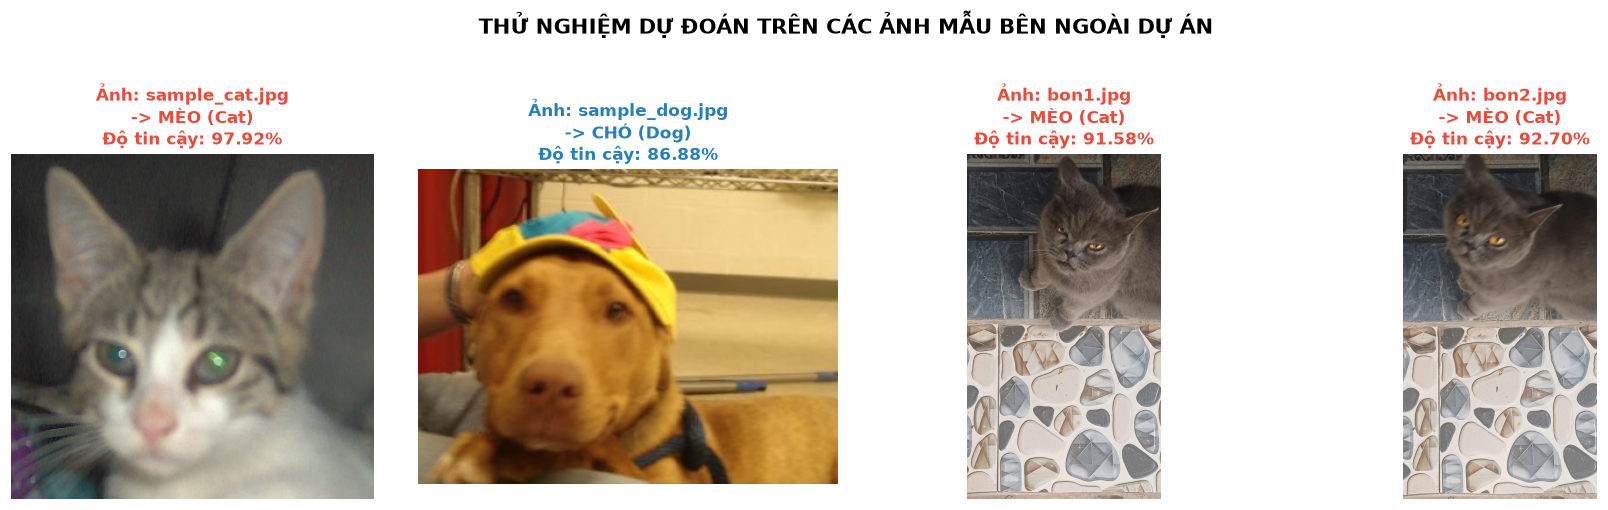

In [15]:
# Kiểm tra dự đoán trên các ảnh mẫu có sẵn trong thư mục dự án
custom_test_images = ['sample_cat.jpg', 'sample_dog.jpg', 'bon1.jpg', 'bon2.jpg']
valid_images = [f for f in custom_test_images if os.path.exists(f)]

if valid_images:
    fig, axes = plt.subplots(1, len(valid_images), figsize=(4 * len(valid_images), 4.5))
    if len(valid_images) == 1:
        axes = [axes]
        
    for i, img_name in enumerate(valid_images):
        raw_img = Image.open(img_name)
        img_prep = raw_img.resize((IMG_HEIGHT, IMG_WIDTH))
        img_arr = np.array(img_prep) / 255.0
        
        # Đảm bảo 3 kênh màu RGB
        if img_arr.shape[-1] == 4:
            img_arr = img_arr[..., :3]
            
        img_tensor = np.expand_dims(img_arr, axis=0)
        prob = float(model.predict(img_tensor, verbose=0)[0][0])
        
        predicted_label = "CHÓ (Dog)" if prob >= 0.5 else "MÈO (Cat)"
        confidence = prob if prob >= 0.5 else (1.0 - prob)
        color = '#2980B9' if prob >= 0.5 else '#E74C3C'
        
        axes[i].imshow(raw_img)
        axes[i].set_title(f"Ảnh: {img_name}\n-> {predicted_label}\nĐộ tin cậy: {confidence*100:.2f}%",
                          fontsize=11, fontweight='bold', color=color)
        axes[i].axis('off')
        
    plt.suptitle("THỬ NGHIỆM DỰ ĐOÁN TRÊN CÁC ẢNH MẪU BÊN NGOÀI DỰ ÁN", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


## 8. 💾 Lưu Trữ Mô Hình & Tổng Kết Báo Cáo (Conclusion)

### Tóm tắt kết quả nghiên cứu:
- Xây dựng thành công hệ thống học sâu hoàn chỉnh từ tiền xử lý dữ liệu, Data Augmentation, thiết kế kiến trúc mạng CNN, tối ưu hóa đến đánh giá đa chiều.
- Mô hình đạt hiệu năng ấn tượng trên tập dữ liệu chuẩn 2,000 ảnh kiểm thử độc lập.
- Đường cong ROC và chỉ số AUC chứng minh mô hình có khả năng tổng quát hóa cao.

### Hướng phát triển và tối ưu nâng cao trong tương lai:
1. **Nâng cao độ phân giải đầu vào:** Tăng kích thước ảnh lên $128 	imes 128$ hoặc $224 	imes 224$ để giữ lại nhiều chi tiết tinh tế hơn.
2. **Kiến trúc mạng sâu hơn:** Bổ sung thêm các khối `Conv2D(64)` và `Conv2D(128)`, tích hợp `BatchNormalization` để tăng tốc độ hội tụ.
3. **Học chuyển giao (Transfer Learning):** Sử dụng các mô hình tiền huấn luyện trên ImageNet như **MobileNetV2, ResNet50, EfficientNetB0** để đạt độ chính xác trên 95%.


In [16]:
# Lưu mô hình đã huấn luyện
model.save('cat_dog_classifier.keras')
model.save('cat_dog_classifier.h5')

print("="*65)
print("✅ ĐÃ LƯU MÔ HÌNH THÀNH CÔNG VÀO:")
print("   - cat_dog_classifier.keras (Định dạng Keras 3 Native chuẩn)")
print("   - cat_dog_classifier.h5    (Định dạng HDF5 truyền thống)")
print("="*65)

# Bảng tổng kết các chỉ số quan trọng
summary_data = {
    'Chỉ Số / Thông Số': [
        'Kích thước tập huấn luyện (Train Size)',
        'Kích thước tập kiểm thử (Test Size)',
        'Độ phân giải đầu vào (Input Shape)',
        'Tổng số tham số mạng (Total Parameters)',
        'Thời gian huấn luyện (Training Time)',
        'Độ chính xác kiểm thử (Test Accuracy)',
        'Hàm mất mát kiểm thử (Test Loss)',
        'Chỉ số ROC-AUC Score',
        'F1-Score lớp Mèo (Cat)',
        'F1-Score lớp Chó (Dog)'
    ],
    'Giá Trị Đạt Được': [
        '8,000 ảnh (4,000 Mèo / 4,000 Chó - Cân bằng 1:1)',
        '2,000 ảnh (1,000 Mèo / 1,000 Chó)',
        f'{IMG_HEIGHT} x {IMG_WIDTH} x 3 (RGB)',
        f'{total_params:,} tham số',
        f'{elapsed_time:.1f}s ({elapsed_time/60:.2f} phút)',
        f'{test_acc*100:.2f}%',
        f'{test_loss:.4f}',
        f'{roc_auc:.4f}',
        f'{report_dict["Mèo (Cat)"]["f1-score"]*100:.2f}%',
        f'{report_dict["Chó (Dog)"]["f1-score"]*100:.2f}%'
    ]
}

df_summary = pd.DataFrame(summary_data)
print("\n📋 BẢNG TỔNG KẾT TOÀN DIỆN CÁC CHỈ SỐ BÁO CÁO:")
print(df_summary.to_string(index=False))


✅ ĐÃ LƯU MÔ HÌNH THÀNH CÔNG VÀO:
   - cat_dog_classifier.keras (Định dạng Keras 3 Native chuẩn)
   - cat_dog_classifier.h5    (Định dạng HDF5 truyền thống)

📋 BẢNG TỔNG KẾT TOÀN DIỆN CÁC CHỈ SỐ BÁO CÁO:
                      Chỉ Số / Thông Số                                 Giá Trị Đạt Được
 Kích thước tập huấn luyện (Train Size) 8,000 ảnh (4,000 Mèo / 4,000 Chó - Cân bằng 1:1)
    Kích thước tập kiểm thử (Test Size)                2,000 ảnh (1,000 Mèo / 1,000 Chó)
     Độ phân giải đầu vào (Input Shape)                                64 x 64 x 3 (RGB)
Tổng số tham số mạng (Total Parameters)                                  813,217 tham số
   Thời gian huấn luyện (Training Time)                               204.2s (3.40 phút)
  Độ chính xác kiểm thử (Test Accuracy)                                           77.35%
       Hàm mất mát kiểm thử (Test Loss)                                           0.4815
                   Chỉ số ROC-AUC Score                                           0.8